In [1]:
# conda env 'at3d_pure'

import sys
sys.path.append('/data/keeling/a/johntl3/b/LundstromPub2025/src')

import at3d
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import netCDF4 as nc
from collections import OrderedDict
from util import load_sensor_dict
from util import save_sensor_dict

In [2]:
## INPUT
obs_file = '/data/keeling/a/johntl3/b/LundstromPub2025/CAMP2Ex_RF17/intermediate_data/AT3D_OBS_CAMP2Ex_RF17_default_1400.nc'
rte_grid_file = '/data/keeling/a/johntl3/b/LundstromPub2025/CAMP2Ex_RF17/intermediate_data/RTG_1400.nc'
background_scatterers_file = '/data/keeling/a/johntl3/b/LundstromPub2025/CAMP2Ex_RF17/intermediate_data/MIXTURE_default_0p250.nc'
# cloud_volume_mask_file = '/data/keeling/a/johntl3/b/LundstromPub2025/CAMP2Ex_RF17/intermediate_data/CVM_all_cloud_1400.nc'
config_file_name = '/data/keeling/a/johntl3/b/LundstromPub2025/NK1990_1D_Retrieval/misr_1D_config.json'
# config_file_name = '/data/keeling/a/johntl3/b/LundstromPub2025/configs/misr_config.json'
surface_wind_speed = 0.67 # m/s
# Reff(z) = a*z + b
a = 4.292 # um / km
b = 2.623 # um

# Mie table directory
mie_dir = '/data/keeling/a/johntl3/b/LundstromPub2025/mie_tables/'

## OUTPUT
out_file = './LUT_RF17.nc'
# sd_out = './OBS_RF17.nc'


In [3]:
rte_grid = xr.load_dataset(rte_grid_file)
rte_grid = at3d.grid.make_grid(0.275, 3, 0.275, 3, rte_grid.z.data)
obs = load_sensor_dict(obs_file)

In [4]:
forward_sensors = at3d.containers.SensorsDict()
sensor = at3d.sensor.orthographic_projection(
    wavelength=0.67,
    bounding_box=rte_grid,
    x_resolution=0.275,
    y_resolution=0.275,
    azimuth=0,
    zenith=0,
    altitude='TOA',
    stokes='I',
    sub_pixel_ray_args={'method': None}
)
sensor = sensor.assign_attrs(mu0=obs['MISR']['sensor_list'][4].mu0)
sensor = sensor.assign_attrs(SAA=obs['MISR']['sensor_list'][4].SAA)
forward_sensors.add_sensor('MISR', sensor)

In [5]:
wavelength = 0.67

# Surface wind speed comes from ERA5 reanalysis - 
# see ./ancillary/CAMP2Ex_RF17_ERA5_Surface.ipynb
surfaces = OrderedDict()
m_water = 1.33197 - 1j*2.41e-8
surfaces[wavelength] = at3d.surface.wave_fresnel(np.real(m_water), np.imag(m_water), surface_wind_speed)

numerical_parameters = OrderedDict()
numerical_parameters[wavelength] = at3d.configuration.get_config(config_file_name)

sources = OrderedDict()
sources[wavelength] = at3d.source.solar(
    wavelength,
    -1*obs['MISR']['sensor_list'][0].mu0,
    obs['MISR']['sensor_list'][0].SAA,
    solarflux=1.0,
    skyrad=0.0
)

background_optical_scatterers = OrderedDict()
merged_properties = xr.load_dataset(background_scatterers_file)
background_optical_scatterers[wavelength] = {}
background_optical_scatterers[wavelength]['background'] = merged_properties.isel(x=slice(0,3),y=slice(0,3))

mie_mono_table = at3d.mie.get_mono_table(
    'Water',
    (wavelength, wavelength),
    max_integration_radius=65.0,
    minimum_effective_radius=5.5,
    relative_dir=mie_dir,
    verbose=False
)
mie_mono_tables = OrderedDict()
mie_mono_tables[wavelength] = mie_mono_table
# mie_mono_table.to_netcdf('../mie_tables/red_mie_table.nc')

cloud_optical_prop_gen = at3d.medium.OpticalPropertyGenerator(
    'cloud',
    mie_mono_tables,
    at3d.size_distribution.gamma,
    particle_density=1.0,
    maxnphase=None,
    interpolation_mode='exact',
    density_normalization='geometric_extinction',
    reff=np.linspace(1, 30, 20),
    veff=np.linspace(0.01, 0.2, 5)
)


In [6]:

taus = np.logspace(-1, 1.9, 100)
taus[0] = 0
brf = np.zeros(taus.shape)
tau_real = np.zeros(taus.shape)

for i, tau in enumerate(taus):
    cloud = rte_grid.copy(deep=True)
    i_up = 11
    i_low = 5
    # print('cloud from {} km to {} km'.format(rte_grid.z.data[i_low], rte_grid.z.data[i_up]))
    thickness = rte_grid.z.data[i_up] - rte_grid.z.data[i_low]
    ext = np.zeros((rte_grid.dims['x'], rte_grid.dims['y'], rte_grid.dims['z']))
    ext[:, :, i_low:i_up] = tau/thickness
    cloud['density'] = (['x','y','z'], ext)
    # See ./ancillary/CAMP2Ex_SPEC.ipynb for Re calculation
    reff_profile = a * rte_grid.z.data + b
    reff = np.tile(reff_profile, (rte_grid.dims['x'], rte_grid.dims['y'], 1))
    cloud['reff'] = (['x','y','z'], reff)
    cloud['veff'] = (['x','y','z'], np.ones(cloud.density.shape) * 0.1)
    cloud_optical_properties = cloud_optical_prop_gen(cloud)

    medium = {}
    medium['background'] = merged_properties.isel(x=slice(0,3),y=slice(0,3))
    medium['cloud'] = cloud_optical_properties[wavelength]

    solvers = at3d.containers.SolversDict()
    solver = at3d.solver.RTE(
        numerical_params=numerical_parameters[wavelength],
        medium=medium,
        source=sources[wavelength],
        surface=surfaces[wavelength],
        num_stokes=1)
    solvers.add_solver(wavelength, solver)

    tau_real[i] = np.unique(solvers[0.67].medium['cloud'].extinction.integrate('z').data)[0]

    forward_sensors.get_measurements(solvers)

    cam = forward_sensors['MISR']['sensor_list'][0]
    assert len(np.unique(cam.I.data*np.pi/cam.mu0)) == 1
    brf[i] = np.unique(cam.I.data*np.pi/cam.mu0)[0]

  ! Iter Log(Sol)  SplitCrit  Npoints  Nsh(avg)   [Radiance 0.670 micron]
     1  -0.975  0.472E-01      144   256.00  1.000   [Radiance 0.670 micron]
     2  -1.454  0.478E-01      144   256.00  1.000   [Radiance 0.670 micron]
     3  -1.999  0.482E-01      144   256.00  1.000   [Radiance 0.670 micron]
     4  -2.095  0.129E-01      153   256.00  1.000   [Radiance 0.670 micron]
     5  -1.454  0.143E-01      153   256.00  1.000   [Radiance 0.670 micron]
     6  -1.934  0.128E-01      153   256.00  1.000   [Radiance 0.670 micron]
     7  -2.237  0.127E-01      153   256.00  1.000   [Radiance 0.670 micron]
     8  -2.866  0.126E-01      153   256.00  1.000   [Radiance 0.670 micron]
     9  -3.164  0.126E-01      153   256.00  1.000   [Radiance 0.670 micron]
    10  -3.982  0.126E-01      153   256.00  1.000   [Radiance 0.670 micron]
    11  -4.264  0.126E-01      153   256.00  1.000   [Radiance 0.670 micron]
 ! Iterations:     11     Final Criterion:  0.000054   [Radiance 0.670 micron]


/data/keeling/a/johntl3/miniconda3/envs/at3d_pure/lib/python3.10/site-packages/at3d/solver.py:2337: UserWarning: Number of SHDOM grid cells with optical depth greater than 2: '8'. Max cell optical depth: '2.076920986175537'
  warnings.warn("Number of SHDOM grid cells with optical depth greater than 2: '{}'. "


  ! Iter Log(Sol)  SplitCrit  Npoints  Nsh(avg)   [Radiance 0.670 micron]
     1  -0.987  0.179E+00      144   256.00  1.000   [Radiance 0.670 micron]
     2  -1.362  0.188E+00      144   256.00  1.000   [Radiance 0.670 micron]
     3  -1.637  0.193E+00      144   256.00  1.000   [Radiance 0.670 micron]
     4  -1.710  0.631E-01      153   256.00  1.000   [Radiance 0.670 micron]
     5  -1.520  0.572E-01      153   256.00  1.000   [Radiance 0.670 micron]
     6  -2.120  0.597E-01      153   256.00  1.000   [Radiance 0.670 micron]
     7  -2.382  0.603E-01      153   256.00  1.000   [Radiance 0.670 micron]
     8  -2.440  0.492E-01      180   256.00  1.000   [Radiance 0.670 micron]
     9  -1.607  0.228E-01      198   256.00  1.000   [Radiance 0.670 micron]
    10  -2.288  0.220E-01      198   256.00  1.000   [Radiance 0.670 micron]
    11  -2.678  0.227E-01      198   256.00  1.000   [Radiance 0.670 micron]
    12  -2.782  0.228E-01      198   256.00  1.000   [Radiance 0.670 micron]
  

/data/keeling/a/johntl3/miniconda3/envs/at3d_pure/lib/python3.10/site-packages/at3d/solver.py:2337: UserWarning: Number of SHDOM grid cells with optical depth greater than 2: '20'. Max cell optical depth: '2.22040057182312'
  warnings.warn("Number of SHDOM grid cells with optical depth greater than 2: '{}'. "


  ! Iter Log(Sol)  SplitCrit  Npoints  Nsh(avg)   [Radiance 0.670 micron]
     1  -1.000  0.191E+00      144   256.00  1.000   [Radiance 0.670 micron]
     2  -1.382  0.200E+00      144   256.00  1.000   [Radiance 0.670 micron]
     3  -1.631  0.672E-01      153   256.00  1.000   [Radiance 0.670 micron]
     4  -1.753  0.655E-01      153   256.00  1.000   [Radiance 0.670 micron]
     5  -2.017  0.645E-01      153   256.00  1.000   [Radiance 0.670 micron]
     6  -2.128  0.647E-01      153   256.00  1.000   [Radiance 0.670 micron]
     7  -2.491  0.551E-01      171   256.00  1.000   [Radiance 0.670 micron]
     8  -2.459  0.237E-01      198   256.00  1.000   [Radiance 0.670 micron]
     9  -2.343  0.228E-01      198   256.00  1.000   [Radiance 0.670 micron]
    10  -2.617  0.236E-01      198   256.00  1.000   [Radiance 0.670 micron]
    11  -2.763  0.239E-01      198   256.00  1.000   [Radiance 0.670 micron]
    12  -2.805  0.238E-01      198   256.00  1.000   [Radiance 0.670 micron]
  

...

  ! Iter Log(Sol)  SplitCrit  Npoints  Nsh(avg)   [Radiance 0.670 micron]
     1  -1.190  0.617E+00      144   256.00  1.000   [Radiance 0.670 micron]
     2  -2.121  0.614E+00      144   256.00  1.000   [Radiance 0.670 micron]
     3  -1.536  0.223E+00      162   256.00  1.000   [Radiance 0.670 micron]
     4  -1.691  0.215E+00      171   256.00  1.000   [Radiance 0.670 micron]
     5  -2.212  0.130E+00      189   256.00  1.000   [Radiance 0.670 micron]
     6  -2.026  0.870E-01      216   256.00  1.000   [Radiance 0.670 micron]
     7  -2.097  0.709E-01      225   256.00  1.000   [Radiance 0.670 micron]
     8  -2.532  0.715E-01      225   256.00  1.000   [Radiance 0.670 micron]
     9  -2.514  0.346E-01      288   256.00  1.000   [Radiance 0.670 micron]
    10  -2.412  0.346E-01      288   256.00  1.000   [Radiance 0.670 micron]
    11  -2.870  0.347E-01      288   256.00  1.000   [Radiance 0.670 micron]
    12  -2.944  0.293E-01      342   256.00  1.000   [Radiance 0.670 micron]
  

/data/keeling/a/johntl3/miniconda3/envs/at3d_pure/lib/python3.10/site-packages/at3d/solver.py:2337: UserWarning: Number of SHDOM grid cells with optical depth greater than 2: '28'. Max cell optical depth: '16.661020278930664'
  warnings.warn("Number of SHDOM grid cells with optical depth greater than 2: '{}'. "


  ! Iter Log(Sol)  SplitCrit  Npoints  Nsh(avg)   [Radiance 0.670 micron]
     1  -1.193  0.623E+00      144   256.00  1.000   [Radiance 0.670 micron]
     2  -2.124  0.620E+00      144   256.00  1.000   [Radiance 0.670 micron]
     3  -1.529  0.227E+00      162   256.00  1.000   [Radiance 0.670 micron]
     4  -1.677  0.219E+00      171   256.00  1.000   [Radiance 0.670 micron]
     5  -2.222  0.138E+00      189   256.00  1.000   [Radiance 0.670 micron]
     6  -2.030  0.900E-01      216   256.00  1.000   [Radiance 0.670 micron]
     7  -2.063  0.725E-01      225   256.00  1.000   [Radiance 0.670 micron]
     8  -2.506  0.730E-01      225   256.00  1.000   [Radiance 0.670 micron]
     9  -2.494  0.370E-01      288   256.00  1.000   [Radiance 0.670 micron]
    10  -2.401  0.370E-01      288   256.00  1.000   [Radiance 0.670 micron]
    11  -2.837  0.371E-01      288   256.00  1.000   [Radiance 0.670 micron]
    12  -2.937  0.282E-01      351   256.00  1.000   [Radiance 0.670 micron]
  

/data/keeling/a/johntl3/miniconda3/envs/at3d_pure/lib/python3.10/site-packages/at3d/solver.py:2337: UserWarning: Number of SHDOM grid cells with optical depth greater than 2: '28'. Max cell optical depth: '17.822120666503906'
  warnings.warn("Number of SHDOM grid cells with optical depth greater than 2: '{}'. "


  ! Iter Log(Sol)  SplitCrit  Npoints  Nsh(avg)   [Radiance 0.670 micron]
     1  -1.197  0.629E+00      144   256.00  1.000   [Radiance 0.670 micron]
     2  -2.127  0.626E+00      144   256.00  1.000   [Radiance 0.670 micron]
     3  -1.523  0.232E+00      162   256.00  1.000   [Radiance 0.670 micron]
     4  -1.663  0.222E+00      171   256.00  1.000   [Radiance 0.670 micron]
     5  -2.226  0.146E+00      189   256.00  1.000   [Radiance 0.670 micron]
     6  -2.035  0.930E-01      216   256.00  1.000   [Radiance 0.670 micron]
     7  -2.034  0.741E-01      225   256.00  1.000   [Radiance 0.670 micron]
     8  -2.476  0.745E-01      225   256.00  1.000   [Radiance 0.670 micron]
     9  -2.473  0.396E-01      288   256.00  1.000   [Radiance 0.670 micron]
    10  -2.391  0.396E-01      288   256.00  1.000   [Radiance 0.670 micron]
    11  -2.806  0.397E-01      288   256.00  1.000   [Radiance 0.670 micron]
    12  -2.919  0.286E-01      351   256.00  1.000   [Radiance 0.670 micron]
  

In [7]:
LUT = xr.Dataset(
    coords=dict(
        brf=brf
    ),
    data_vars=dict(
        tau=(['brf'], tau_real)
    )
)
LUT.to_netcdf(out_file)

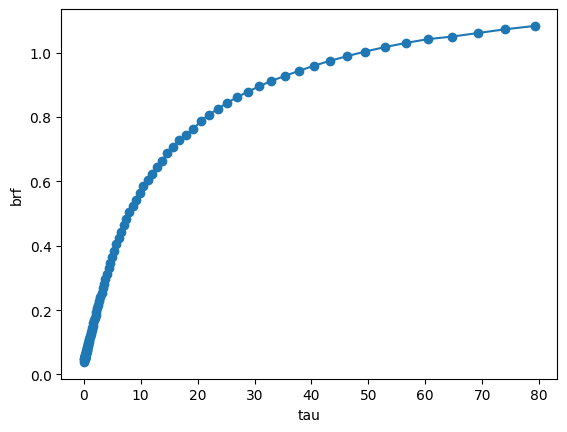

In [8]:
LUT.tau.plot(y='brf', marker='o')